# L3.1 · Credit classification — two ways to flag loans

**Day 3 slides** 4, 5 and 10

### The problem

We have the information on a loan application and want to sort cases for review. Does a learned formula or a vote from similar loans give better scores?

### What we’re doing

Compare logistic regression and k-nearest neighbours, check what their chances mean, then choose a cutoff on validation data.

### Why we’re doing it

A review decision depends on both the model and how we use its score. Checking these separately helps us explain the choice.

Read the text above a code cell, then click the cell and press
**Shift + Enter**. Run from the top. The files contain synthetic course data.

**What the model guesses.** The default model guesses a yes-or-no class. The risk-grade model later in the notebook guesses one of five classes.

## Setup · Open the data

Use the same dated sample as D3.1. Leave the loan’s later outcomes, such as collection calls, out of the input list. Leave the 2025 labels aside until the final check. Run this cell as written. The import lines make the tools
available. The folder lines find the supplied data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pathlib import Path

here = Path.cwd()
data = next((folder / "data" for folder in (here, *here.parents)
             if (folder / "data" / "loan_applications.csv").is_file()), None)
if data is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

inputs = ["aecb_score", "debt_burden_ratio", "loan_amount_aed", "num_prior_delinquencies_24m"]
columns = ["application_date", "default_12m", "risk_grade"] + inputs
loans = pd.read_csv(data / "loan_applications.csv", usecols=columns, parse_dates=["application_date"])
loans = loans.dropna(subset=inputs + ["default_12m"])
year = loans["application_date"].dt.year
train = loans[year <= 2023].sample(4000, random_state=42)
validation = loans[year == 2024].sample(2500, random_state=42)
test = loans[year == 2025].sample(2500, random_state=42)

display(train[inputs + ["default_12m"]].head(4))

,aecb_score,debt_burden_ratio,loan_amount_aed,num_prior_delinquencies_24m,default_12m
220135,735.0,0.5000,121900.0,0,0
86305,749.0,0.5000,145100.0,0,0
186100,715.0,0.2754,31400.0,0,0
120930,696.0,0.2105,73400.0,2,0


## 1 · Read what the model learned

**What we’re doing.** Fit logistic regression and show how each input changes the odds at a fixed value of the other inputs.

**Why.** The model adds weighted inputs on a scale called log-odds. Converting a weight with exp gives an odds multiplier. Odds compare the chance of yes with the chance of no.

**Look for.** A multiplier above one means higher odds. Since we scaled the inputs, it refers to an increase of one training standard deviation.

In [2]:
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
logit.fit(train[inputs], train["default_12m"])
weights = logit.named_steps["logisticregression"].coef_[0]
display(pd.DataFrame({"Input": inputs, "Log-odds weight": weights, "Odds multiplier": np.exp(weights)}).round(3))
actual = validation["default_12m"]
chance = logit.predict_proba(validation[inputs])[:, 1]

,Input,Log-odds weight,Odds multiplier
0,aecb_score,-1.004,0.366
1,debt_burden_ratio,0.635,1.887
2,loan_amount_aed,-0.400,0.670
3,num_prior_delinquencies_24m,0.372,1.450


**What logistic regression is doing.** The model learns a straight
boundary for any fixed cutoff in the inputs. The S-shaped curve turns
its score into a chance. The setting C controls how strongly large
weights are penalised. The model in this lab uses the default C.

## 2 · Let similar loans vote

**What we’re doing.** Give k-NN the same four inputs. Compare a vote by five neighbours on the original numbers and on scaled numbers, then try a larger vote.

**Why.** Loan amounts are in AED and the debt ratio is a small fraction. Scaling stops one input from dominating distance just because of its units.

**Look for.** Average precision measures how well the scores bring defaults toward the top. Use this table as a comparison on 2024 loans.

In [3]:
options = {
    "5 neighbours · raw units": KNeighborsClassifier(n_neighbors=5),
    "5 neighbours · scaled": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "25 neighbours · scaled": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
}
scores = {}
for label, model in options.items():
    model.fit(train[inputs], train["default_12m"])
    scores[label] = average_precision_score(actual, model.predict_proba(validation[inputs])[:, 1])
display(pd.Series(scores, name="Validation average precision").round(3))

5 neighbours · raw units    0.075
5 neighbours · scaled       0.139
25 neighbours · scaled      0.199
Name: Validation average precision, dtype: float64

**Revisit the vote.** KNN stores training examples and looks them up
when making a guess. A small vote can follow individual examples
closely. Euclidean distance measures straight-line distance. Manhattan
distance adds the separate changes in each input. See
[Day 2’s neighbour-vote demo](../../Day2/Basic_Demos/02_KNN_and_SVM_Classifiers.ipynb)
for a one-input example.

## 3 · Check what 10% means

**What we’re doing.** Group loans with similar model chances and compare each group’s average chance with its actual default share. Repeat for a model trained with class weights.

**Why.** A well-calibrated chance of 10% should be close to 10 defaults in 100 similar cases. Giving defaults more training weight can change the scale of those chances.

**Look for.** Dots near the diagonal indicate closer agreement. The Brier score averages squared errors in predicted chances. Smaller is better on these same rows.

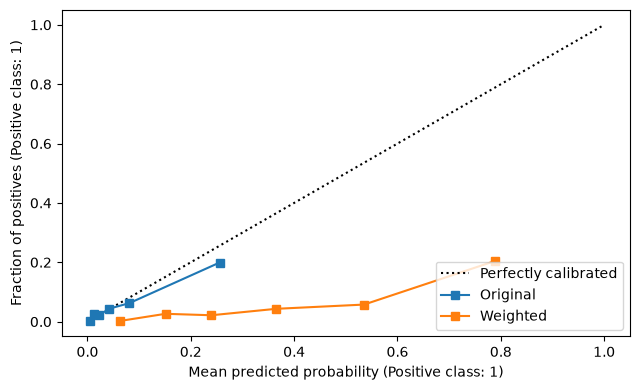

Brier · original: 0.051
Brier · weighted: 0.175


In [4]:
weighted = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=500))
weighted.fit(train[inputs], train["default_12m"])
weighted_chance = weighted.predict_proba(validation[inputs])[:, 1]
fig, ax = plt.subplots(figsize=(6.5, 4))
CalibrationDisplay.from_predictions(actual, chance, n_bins=6, strategy="quantile", name="Original", ax=ax)
CalibrationDisplay.from_predictions(actual, weighted_chance, n_bins=6, strategy="quantile", name="Weighted", ax=ax)
plt.tight_layout()
plt.show()
print("Brier · original:", round(brier_score_loss(actual, chance), 3))
print("Brier · weighted:", round(brier_score_loss(actual, weighted_chance), 3))

## 4 · Choose a cutoff with a limit on reviews

**What we’re doing.** Try several cutoffs for the original logistic model. Keep choices that clear at least 80% of applications in this exercise, then choose the lowest-cost one.

**Why.** The review team’s capacity changes which cutoffs are practical. The cost rule here charges five points for a missed default and one for an extra review.

**Look for.** The first row of the filtered table is the choice for this exercise. These costs and the 80% limit are teaching assumptions.

In [5]:
options = []
for cutoff in np.arange(0.05, 0.51, 0.05).round(2):
    flag = chance >= cutoff
    missed = ((actual == 1) & ~flag).sum()
    extra = ((actual == 0) & flag).sum()
    options.append([cutoff, (~flag).mean(), 5 * missed + extra])
cutoffs = pd.DataFrame(options, columns=["Cutoff", "Share cleared", "Cost points"])
feasible = cutoffs[cutoffs["Share cleared"] >= 0.80].sort_values("Cost points")
display(feasible.round(3))
chosen_cutoff = feasible.iloc[0]["Cutoff"]

,Cutoff,Share cleared,Cost points
2,0.15,0.864,618
3,0.20,0.908,639
4,0.25,0.934,640
5,0.30,0.957,650
6,0.35,0.968,652
7,0.40,0.976,661
8,0.45,0.986,686
1,0.10,0.802,690
9,0.50,0.989,701


## 5 · Guess one of five risk grades

**What we’re doing.** Fit a classification model with the recorded grade as the answer. Print the five chances for two validation examples.

**Why.** Some classification questions have more than two answers. A multiclass model can compare all five labels in one go.

**Look for.** Each row’s chances add to about one. The largest chance is the model’s guess. Grade is the answer in this cell and stays outside its input list.

In [6]:
graded = train.dropna(subset=["risk_grade"])
grader = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
grader.fit(graded[inputs], graded["risk_grade"])
two = validation[inputs].head(2)
grade_chances = pd.DataFrame(grader.predict_proba(two), columns=grader.classes_)
grade_chances["Guess"] = grader.predict(two)
display(grade_chances.round(3))

,A,B,C,D,E,Guess
0,0.745,0.186,0.060,0.009,0.0,A
1,0.950,0.045,0.004,0.000,0.0,A


**Two ways to handle several labels.** A multinomial model uses a check
called softmax to turn its scores into chances that add to one.
One-vs-rest fits one yes-or-no model per label, with the other labels
grouped together for that check.

### Give every grade a say

**What we’re doing.** Calculate one F1 score for each grade.
Show two ways to average those scores.

**Why.** Macro F1 gives every grade the same weight. Weighted F1 gives
more weight to grades that occur more often. Looking at the individual
scores alongside both averages helps us see how the model treats a rare grade.

**Look for.** Compare the number of examples next to each grade
with the grade’s score.

In [7]:
from sklearn.metrics import f1_score

checked = validation.dropna(subset=["risk_grade"])
correct_grade = checked["risk_grade"]
guess_grade = grader.predict(checked[inputs])
grades = grader.classes_
scores = f1_score(correct_grade, guess_grade, labels=grades, average=None, zero_division=0)
counts = correct_grade.value_counts().reindex(grades, fill_value=0)
display(pd.DataFrame({"Grade": grades, "Rows": counts.to_numpy(), "F1": scores}).round(3))
print("Macro F1:", round(scores.mean(), 3))
print("Weighted F1:", round(np.average(scores, weights=counts), 3))

,Grade,Rows,F1
0,A,1232,0.809
1,B,533,0.330
2,C,314,0.264
3,D,224,0.248
4,E,197,0.622


Macro F1: 0.454
Weighted F1: 0.573


## 6 · Open the final year

**What we’re doing.** Apply the chosen cutoff to the 2025 loans once and record the result.

**Why.** A later group gives the team a fresh check. Recording the model inputs and the cutoff makes the result easier to reproduce.

**Look for.** The two counts show the total review load and how many of those flags were recorded defaults.

In [8]:
later_chance = logit.predict_proba(test[inputs])[:, 1]
flag = later_chance >= chosen_cutoff
later_actual = test["default_12m"]
caught = ((later_actual == 1) & flag).sum()
print(f"Cutoff: {chosen_cutoff:.2f} · 2025 ROC AUC: {roc_auc_score(later_actual, later_chance):.3f}")
print(f"Flagged {flag.sum()} of {len(test)}. Caught {caught} of {later_actual.sum()} defaults.")

Cutoff: 0.15 · 2025 ROC AUC: 0.830
Flagged 338 of 2500. Caught 90 of 174 defaults.


### Your turn

Point to the data used to choose the cutoff and the data used to report its final result. Explain why they come from different years.